# Comprehensive CNN Demonstration on Grayscale Images with Model Checkpointing and Interactive UI

This Colab notebook demonstrates a complete workflow for training a Convolutional Neural Network (CNN) on grayscale images, with capabilities for saving/loading model checkpoints, interactive evaluation, and hyperparameter tuning. We'll use the **CIFAR-10** dataset converted to grayscale as our example.

In [ ]:
# Remove old checkpoints if needed
!rm -f models/cnn_grayscale_epoch_*.h5
!rm -f models/cnn_grayscale_best.h5
!rm -f models/cnn_grayscale_final.h5

import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
# import tensorflow_addons as tfa  # <-- NOT NEEDED
from IPython.display import clear_output
import ipywidgets as widgets
from ipywidgets import interact, interactive, fixed, interact_manual
import pickle

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Create directories for saving models and logs
os.makedirs('models', exist_ok=True)
os.makedirs('logs', exist_ok=True)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.19.0


## 2. Data Loading and EDA (Exploratory Data Analysis)

We'll use CIFAR-10 dataset and convert it to grayscale for this demonstration.

In [ ]:
# Load CIFAR-10 dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

# CIFAR-10 class names
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

# Convert images to grayscale
# Using the luminance formula: 0.2989*R + 0.5870*G + 0.1140*B
def rgb_to_grayscale(images):
    """Convert RGB images to grayscale using luminance weights"""
    return np.dot(images[...,:3], [0.2989, 0.5870, 0.1140])

x_train_gray = rgb_to_grayscale(x_train).astype(np.float32)
x_test_gray = rgb_to_grayscale(x_test).astype(np.float32)

# Normalize pixel values to [0, 1]
x_train_gray /= 255.0
x_test_gray /= 255.0

# Reshape to add channel dimension (required for CNN)
x_train_gray = x_train_gray.reshape(-1, 32, 32, 1)
x_test_gray = x_test_gray.reshape(-1, 32, 32, 1)

# Convert labels to categorical one-hot encoding
y_train_cat = keras.utils.to_categorical(y_train, 10)
y_test_cat = keras.utils.to_categorical(y_test, 10)

print(f"Training data shape: {x_train_gray.shape}")
print(f"Test data shape: {x_test_gray.shape}")
print(f"Number of classes: {len(class_names)}")

Training data shape: (50000, 32, 32, 1)
Test data shape: (10000, 32, 32, 1)
Number of classes: 10


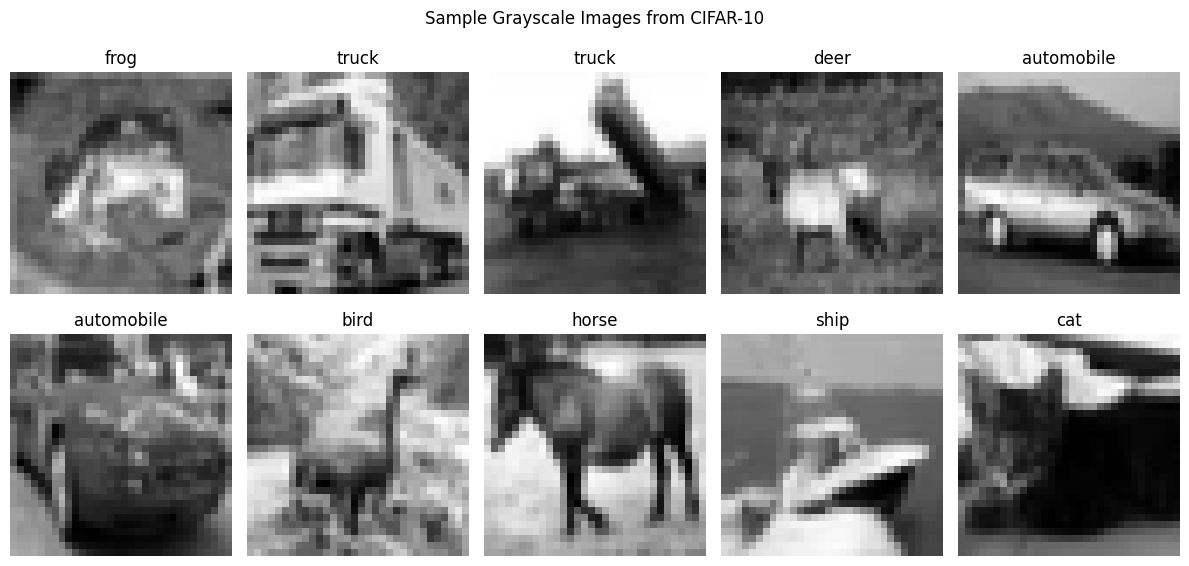

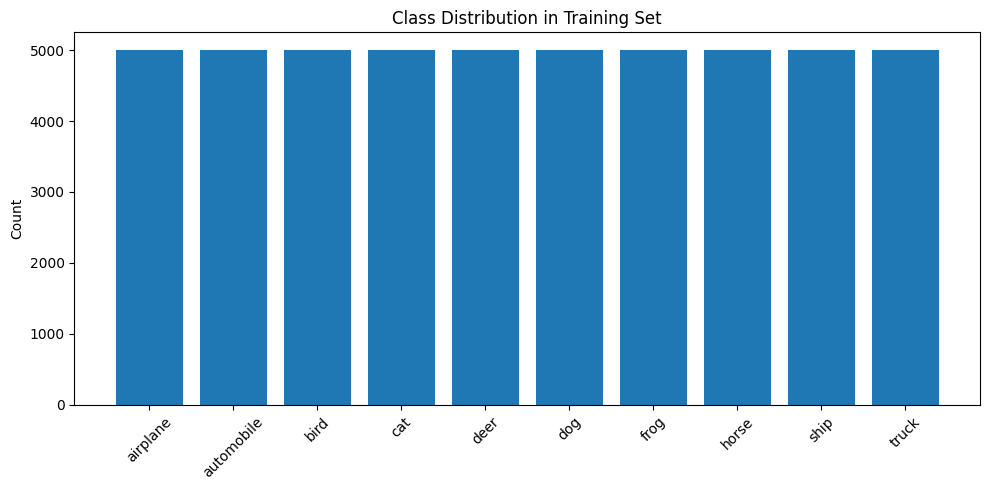

In [ ]:
# Visualize sample grayscale images
plt.figure(figsize=(12, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train_gray[i].squeeze(), cmap='gray')
    plt.title(class_names[y_train[i][0]])
    plt.axis('off')
plt.suptitle('Sample Grayscale Images from CIFAR-10')
plt.tight_layout()
plt.show()

# Class distribution
plt.figure(figsize=(10, 5))
unique, counts = np.unique(y_train, return_counts=True)
plt.bar(class_names, counts)
plt.title('Class Distribution in Training Set')
plt.xticks(rotation=45)
plt.ylabel('Count')
plt.tight_layout()
plt.show()

## 3. Model Architecture

We'll define a simple but effective CNN architecture suitable for grayscale images.

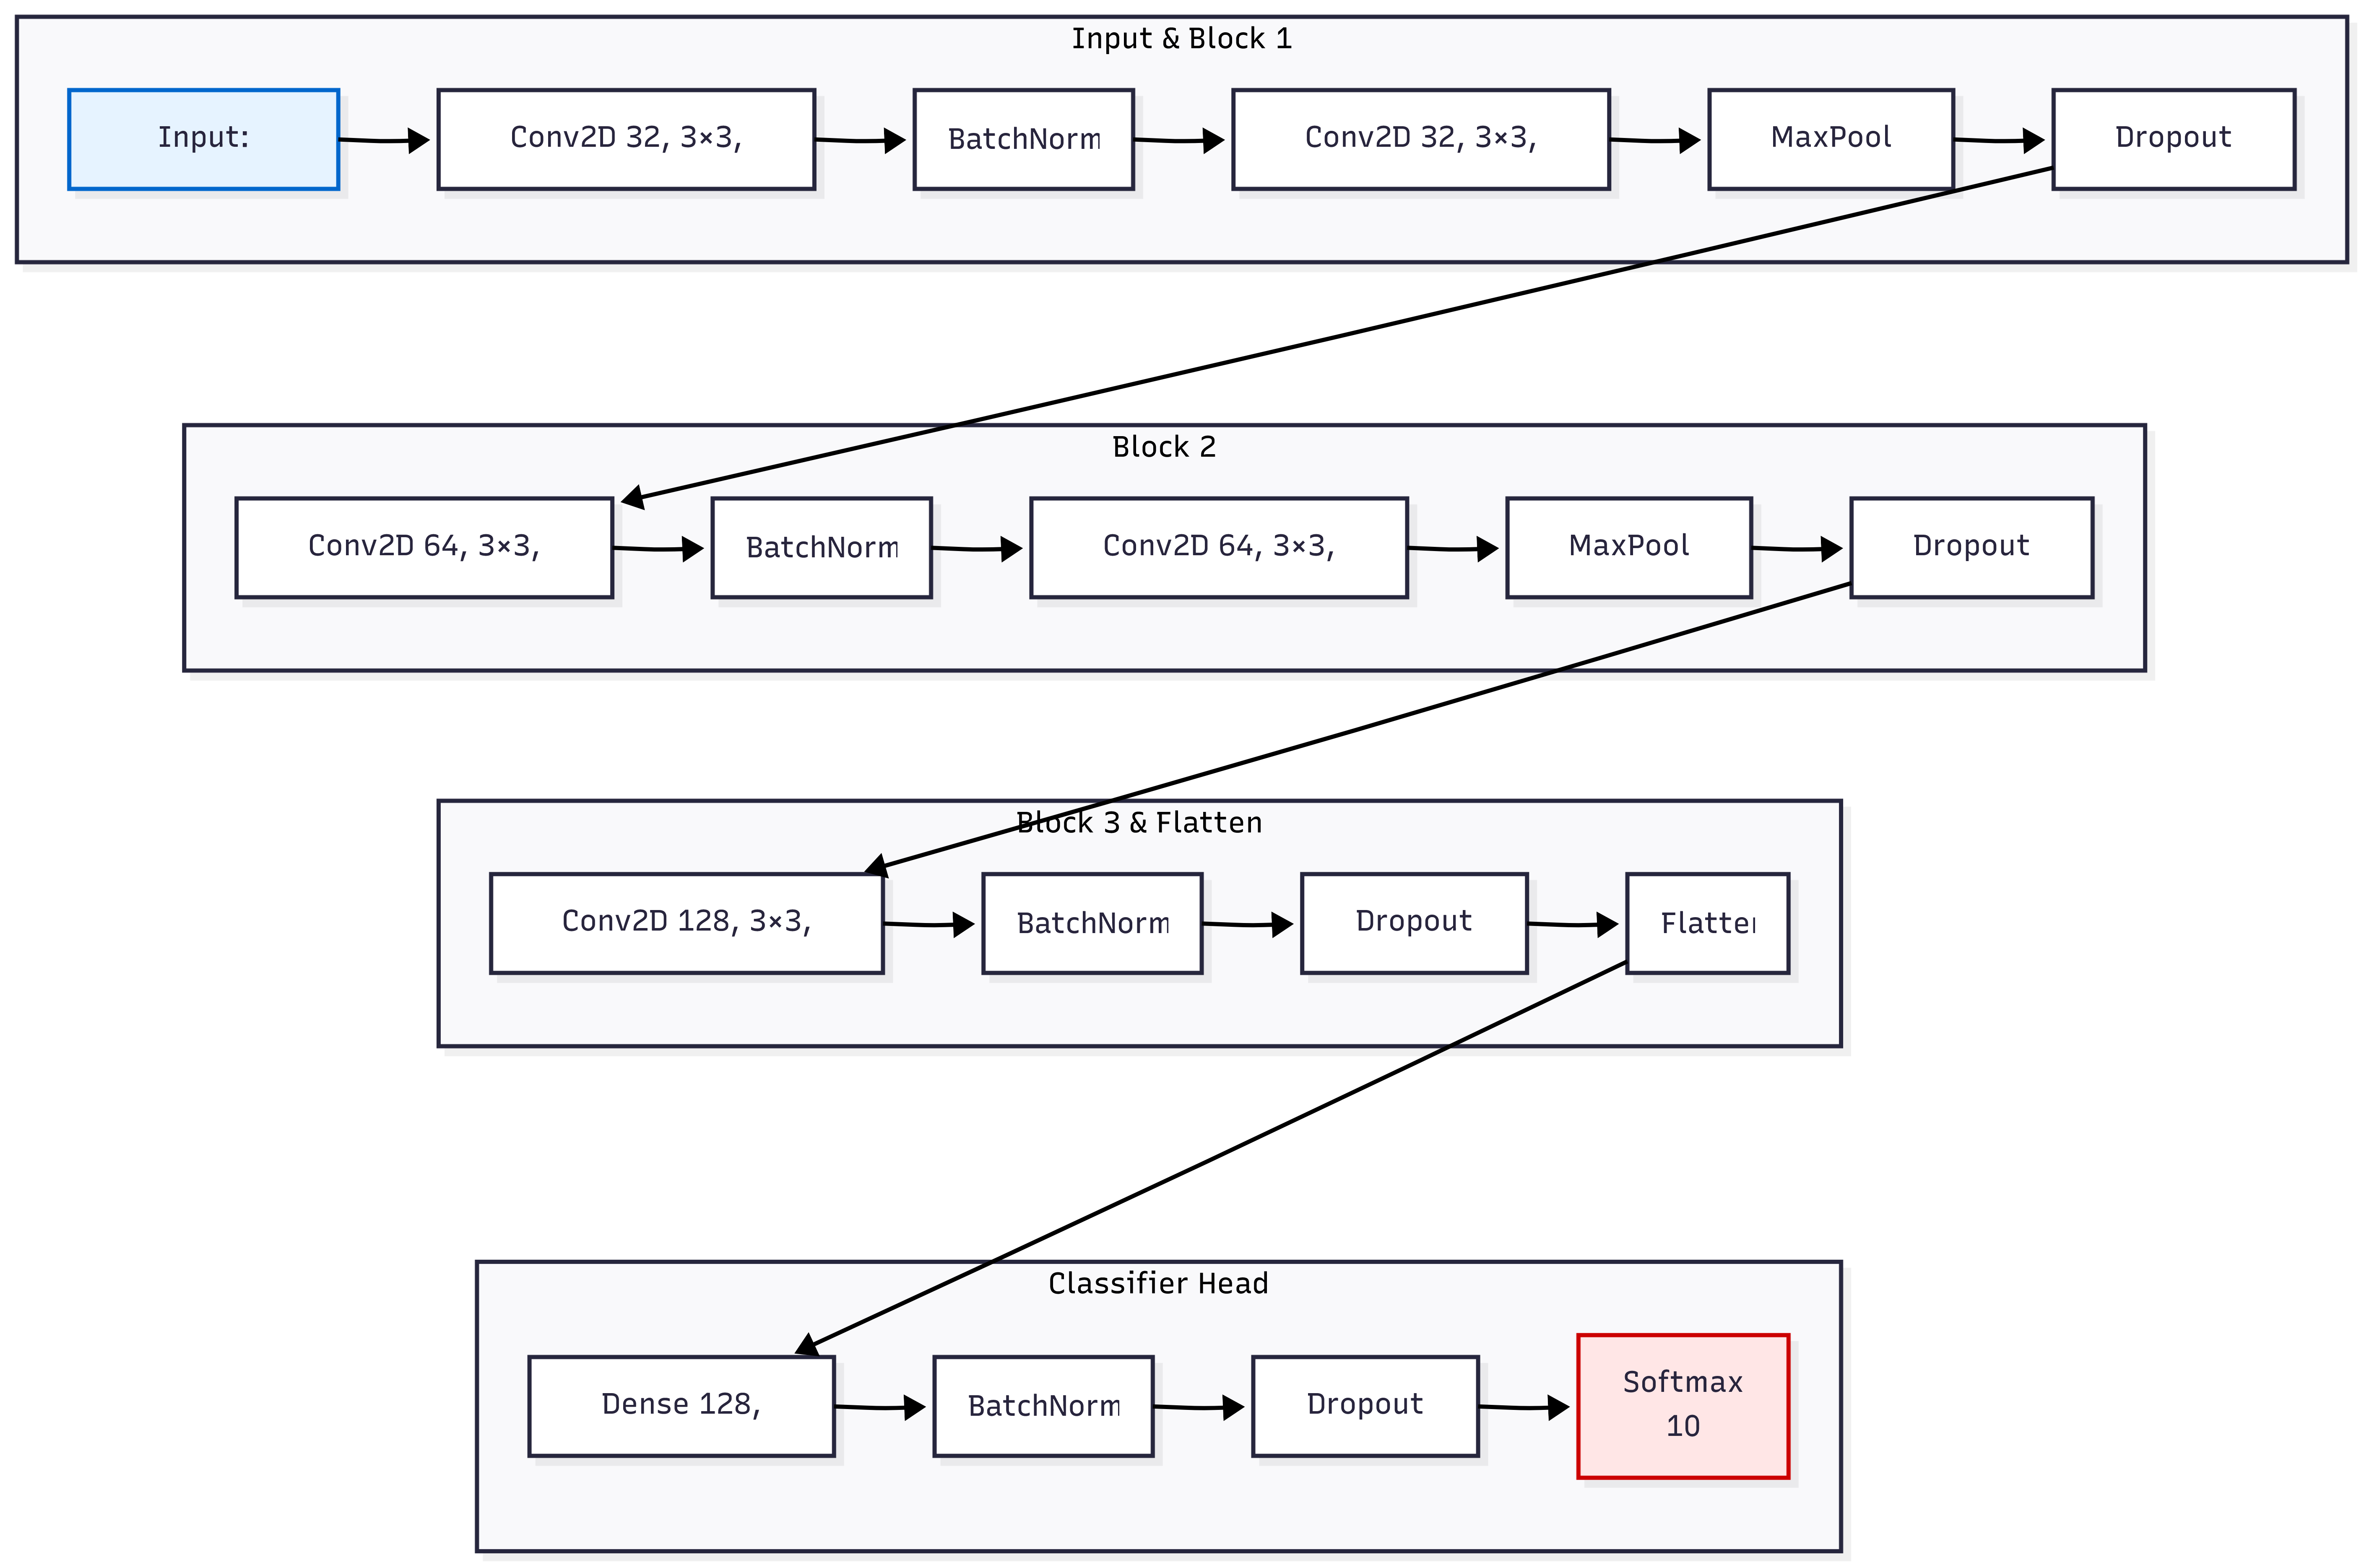

In [ ]:
def create_cnn_model(input_shape=(32, 32, 1), num_classes=10, dropout_rate=0.5):
    """
    Create a CNN model for grayscale image classification.

    Args:
        input_shape: Shape of input images (height, width, channels)
        num_classes: Number of output classes
        dropout_rate: Dropout rate for regularization

    Returns:
        Compiled Keras model
    """
    model = keras.Sequential([
        # First Convolutional Block
        layers.Conv2D(32, (3, 3), activation='relu', input_shape=input_shape),
        layers.BatchNormalization(),
        layers.Conv2D(32, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(dropout_rate/2),

        # Second Convolutional Block
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(dropout_rate/2),

        # Third Convolutional Block
        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(dropout_rate),

        # Fully Connected Layers
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(dropout_rate),
        layers.Dense(num_classes, activation='softmax')
    ])

    # Compile the model
    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

# Create initial model
model = create_cnn_model()
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_30 (Conv2D)              │ (None, 30, 30, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_24          │ (None, 30, 30, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_31 (Conv2D)              │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_24 (Dropout)            │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_32 (Conv2D)              │ (None, 12, 12, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_25          │ (None, 12, 12, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_33 (Conv2D)              │ (None, 10, 10, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_25 (Dropout)            │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_34 (Conv2D)              │ (None, 3, 3, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_26          │ (None, 3, 3, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_26 (Dropout)            │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 128)            │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_27          │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_27 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 289,130 (1.10 MB)

 Trainable params: 288,426 (1.10 MB)

 Non-trainable params: 704 (2.75 KB)

## 4. Training Setup with Checkpointing

We'll set up callbacks for model checkpointing, early stopping, and learning rate reduction.

In [ ]:
def setup_callbacks(model_name):
    """
    Set up callbacks for training using .keras format.
    """
    # Save best model
    checkpoint_cb = keras.callbacks.ModelCheckpoint(
        filepath=f'models/{model_name}_best.keras',  # 👈 .keras extension
        save_best_only=True,
        monitor='val_accuracy',
        mode='max',
        verbose=1
    )

    # Save every epoch (for resuming)
    snapshot_cb = keras.callbacks.ModelCheckpoint(
        filepath=f'models/{model_name}_epoch_{{epoch:02d}}.keras',  # 👈 .keras
        save_best_only=False,
        verbose=0
    )

    early_stopping_cb = keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    )

    reduce_lr_cb = keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=3,
        min_lr=0.0001
    )

    return [checkpoint_cb, snapshot_cb, early_stopping_cb, reduce_lr_cb]

## 5. Model Training Function

This function handles both initial training and resuming from a checkpoint.

In [ ]:
def train_model(model_name, epochs=10, initial_epoch=0, resume_from=None):
    if resume_from and os.path.exists(resume_from):
        print(f"Loading model from {resume_from}")
        # With .keras, you can load AND keep optimizer state!
        model = keras.models.load_model(resume_from)  # 👈 No need for compile=False!
    else:
        print("Creating new model")
        model = create_cnn_model()

    callbacks = setup_callbacks(model_name)

    history = model.fit(
        x_train_gray, y_train_cat,
        batch_size=32,
        epochs=epochs,
        initial_epoch=initial_epoch,
        validation_data=(x_test_gray, y_test_cat),
        callbacks=callbacks,
        verbose=1
    )

    # Save final model in .keras format
    model.save(f'models/{model_name}_final.keras')  # 👈 .keras

    with open(f'logs/{model_name}_history.pkl', 'wb') as f:
        pickle.dump(history.history, f)

    return model, history

## 6. Initial Training

Let's train the model for a few epochs initially.

In [ ]:
# Train for 5 epochs initially
model, history = train_model('cnn_grayscale', epochs=5)

Creating new model
Epoch 1/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.2693 - loss: 2.3025
Epoch 1: val_accuracy improved from -inf to 0.46070, saving model to models/cnn_grayscale_best.keras
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 23s 9ms/step - accuracy: 0.2694 - loss: 2.3022 - val_accuracy: 0.4607 - val_loss: 1.5078 - learning_rate: 0.0010
Epoch 2/5
1560/1563 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5161 - loss: 1.3690
Epoch 2: val_accuracy improved from 0.46070 to 0.55660, saving model to models/cnn_grayscale_best.keras
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.5162 - loss: 1.3689 - val_accuracy: 0.5566 - val_loss: 1.2625 - learning_rate: 0.0010
Epoch 3/5
1552/1563 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5873 - loss: 1.1709
Epoch 3: val_accuracy did not improve from 0.55660
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.5874 - loss: 1.1706 - val_accuracy: 0.5373 - val_loss: 1.3417 - learning_rate: 0.0010
Epoch 4/5
1562/1563 ━━━━━━━━━━━━━━

## 7. Resume Training from Checkpoint

Now we'll demonstrate how to resume training from a saved checkpoint.

In [ ]:
# Find the latest epoch checkpoint
import glob

def get_latest_checkpoint(model_name):
    """Get latest .keras checkpoint"""
    checkpoints = glob.glob(f'models/{model_name}_epoch_*.keras')  # 👈 .keras
    if not checkpoints:
        return None
    epochs = [int(cp.split('_')[-1].split('.')[0]) for cp in checkpoints]
    latest_epoch = max(epochs)
    return f'models/{model_name}_epoch_{latest_epoch:02d}.keras'  # 👈 .keras

# Get the latest checkpoint
latest_cp = get_latest_checkpoint('cnn_grayscale')
print(f"Latest checkpoint: {latest_cp}")

# Resume training for 5 more epochs
if latest_cp:
    # Extract epoch number to set initial_epoch
    initial_epoch = int(latest_cp.split('_')[-1].split('.')[0])
    model, history = train_model(
        'cnn_grayscale',
        epochs=initial_epoch + 5,
        initial_epoch=initial_epoch,
        resume_from=latest_cp
    )
else:
    print("No checkpoint found to resume from")

Latest checkpoint: models/cnn_grayscale_epoch_05.keras
Loading model from models/cnn_grayscale_epoch_05.keras
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6829 - loss: 0.9292
Epoch 6: val_accuracy improved from -inf to 0.72810, saving model to models/cnn_grayscale_best.keras
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 21s 9ms/step - accuracy: 0.6829 - loss: 0.9292 - val_accuracy: 0.7281 - val_loss: 0.7859 - learning_rate: 0.0010
Epoch 7/10
1555/1563 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6950 - loss: 0.8902
Epoch 7: val_accuracy did not improve from 0.72810
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.6950 - loss: 0.8901 - val_accuracy: 0.7276 - val_loss: 0.7750 - learning_rate: 0.0010
Epoch 8/10
1558/1563 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7080 - loss: 0.8505
Epoch 8: val_accuracy did not improve from 0.72810
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.7080 - loss: 0.8505 - val_accuracy: 0.6729 - val_loss: 0.9422 - learning_rate: 

## 8. Model Evaluation

Evaluate the trained model on the test set.

Test accuracy: 0.7404
Test loss: 0.7462
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step

Classification Report:
              precision    recall  f1-score   support

    airplane       0.75      0.76      0.76      1000
  automobile       0.91      0.87      0.89      1000
        bird       0.64      0.58      0.61      1000
         cat       0.56      0.57      0.56      1000
        deer       0.69      0.76      0.72      1000
         dog       0.79      0.54      0.64      1000
        frog       0.60      0.90      0.72      1000
       horse       0.85      0.74      0.79      1000
        ship       0.88      0.84      0.86      1000
       truck       0.85      0.86      0.85      1000

    accuracy                           0.74     10000
   macro avg       0.75      0.74      0.74     10000
weighted avg       0.75      0.74      0.74     10000



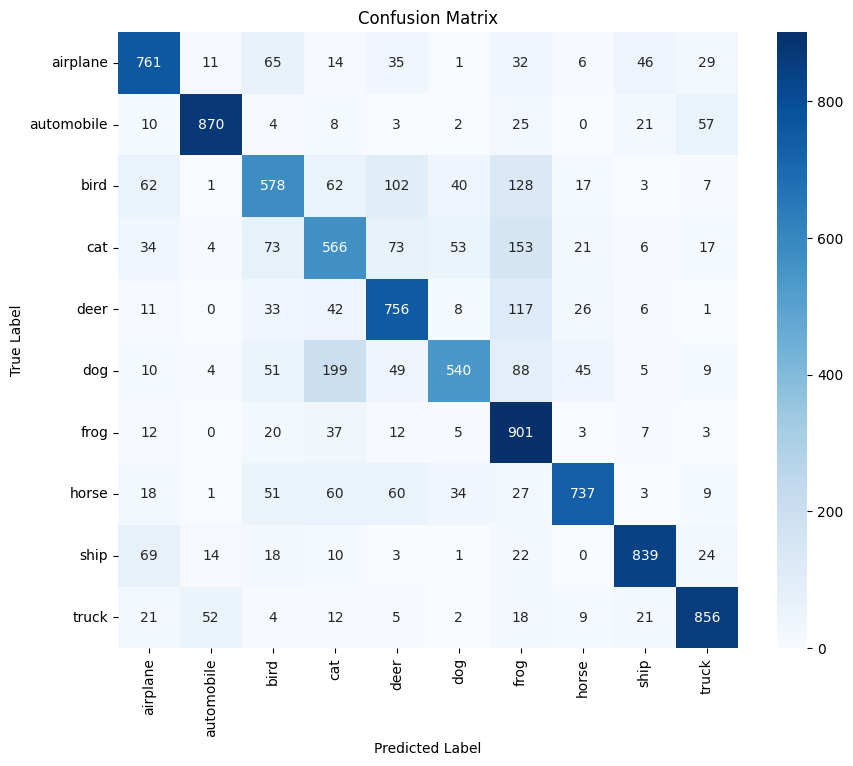

In [ ]:
def evaluate_model(model_path):
    """Evaluate a saved model on the test set"""
    model = keras.models.load_model(model_path)

    # Evaluate
    test_loss, test_acc = model.evaluate(x_test_gray, y_test_cat, verbose=0)
    print(f"Test accuracy: {test_acc:.4f}")
    print(f"Test loss: {test_loss:.4f}")

    # Predictions
    y_pred = model.predict(x_test_gray)
    y_pred_classes = np.argmax(y_pred, axis=1)
    y_true = y_test.flatten()

    # Classification report
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred_classes, target_names=class_names))

    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred_classes)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.title('Confusion Matrix')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.show()

    return model, test_acc

# Evaluate the final model
# AFTER (correct)
model, test_acc = evaluate_model('models/cnn_grayscale_final.keras')

## 9. Hyperparameter Tuning

We'll demonstrate a simple grid search for hyperparameter tuning.

In [ ]:
def tune_hyperparameters():
    """Perform simple hyperparameter tuning"""
    dropout_rates = [0.3, 0.5, 0.7]
    results = {}

    for dr in dropout_rates:
        print(f"\nTraining with dropout rate: {dr}")
        model = create_cnn_model(dropout_rate=dr)

        # Train for a few epochs (in practice, you'd train longer)
        history = model.fit(
            x_train_gray, y_train_cat,
            batch_size=32,
            epochs=3,
            validation_data=(x_test_gray, y_test_cat),
            verbose=0
        )

        # Evaluate
        _, val_acc = model.evaluate(x_test_gray, y_test_cat, verbose=0)
        results[dr] = val_acc
        print(f"Validation accuracy: {val_acc:.4f}")

        # Save model
        model.save(f'models/tuned_dropout_{dr}.h5')

    # Find best dropout rate
    best_dr = max(results, key=results.get)
    print(f"\nBest dropout rate: {best_dr} with accuracy: {results[best_dr]:.4f}")

    return results

# Run hyperparameter tuning
# Note: This is a simplified example; in practice, use Keras Tuner or similar
# results = tune_hyperparameters()

## 10. Interactive Widget UI

Create an interactive widget to load and evaluate different models.

In [ ]:
# @title
def get_available_models():
    """Get list of available model files (.keras and .h5)"""
    model_files = []
    for file in os.listdir('models'):
        if file.endswith('.keras') or file.endswith('.h5'):
            model_files.append(file)
    return sorted(model_files)

def predict_image(model_path, image_index):
    """Make prediction on a specific test image"""
    model = keras.models.load_model(model_path)

    # Get image and true label
    img = x_test_gray[image_index]
    true_label = y_test[image_index][0]

    # Make prediction
    pred = model.predict(img[np.newaxis, ...])
    pred_class = np.argmax(pred)
    confidence = np.max(pred)

    # Display result
    plt.figure(figsize=(6, 3))
    plt.subplot(1, 2, 1)
    plt.imshow(img.squeeze(), cmap='gray')
    plt.title(f'True: {class_names[true_label]}')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.bar(range(len(class_names)), pred[0])
    plt.xticks(range(len(class_names)), class_names, rotation=45)
    plt.title(f'Predicted: {class_names[pred_class]} ({confidence:.2f})')
    plt.tight_layout()
    plt.show()

# Create interactive widget
available_models = get_available_models()
if available_models:
    model_selector = widgets.Dropdown(
        options=available_models,
        value=available_models[0] if available_models else '',
        description='Model:',
    )

    image_slider = widgets.IntSlider(
        value=0,
        min=0,
        max=len(x_test_gray)-1,
        step=1,
        description='Image Index:',
    )

    def update_prediction(model_path, image_index):
        predict_image(os.path.join('models', model_path), image_index)

    interactive_plot = interactive(update_prediction,
                                  model_path=model_selector,
                                  image_index=image_slider)

    display(interactive_plot)
else:
    print("No models found. Please train a model first.")

interactive(children=(Dropdown(description='Model:', options=('cnn_grayscale_best.keras', 'cnn_grayscale_epoch…

HTML(value='<h4>Upload any image (color/grayscale, any size):</h4>')

FileUpload(value={}, accept='image/*', description='Upload Image')

Dropdown(description='Model:', options=('cnn_grayscale_best.keras', 'cnn_grayscale_epoch_01.keras', 'cnn_grays…

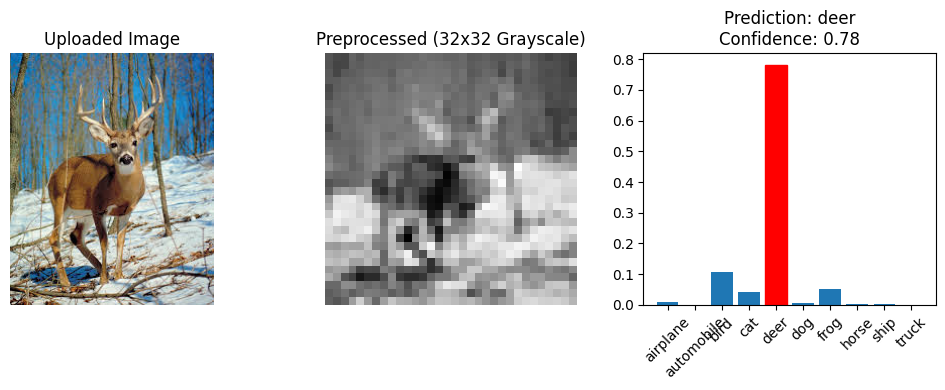

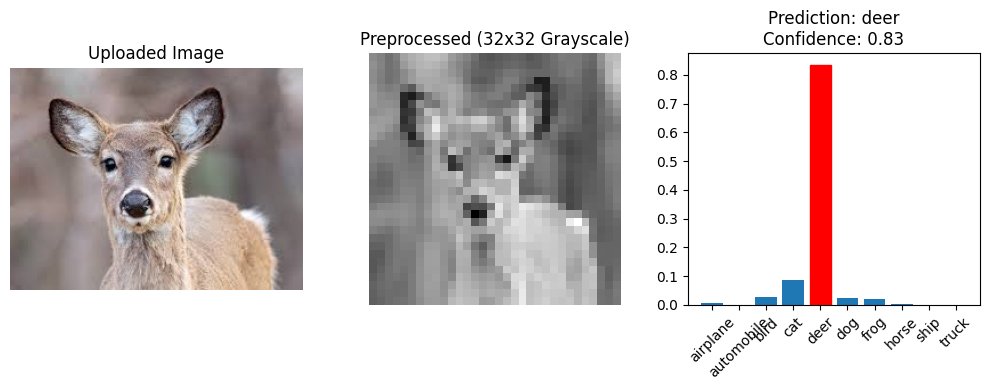

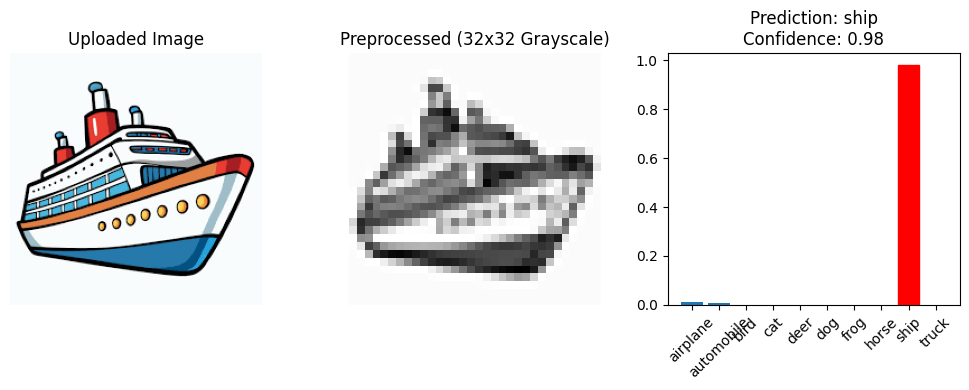

In [ ]:
# @title
import io
from PIL import Image

def predict_uploaded_image(model_path, uploaded_file):
    """
    Predict on a user-uploaded image file.

    Args:
        model_path: Path to trained .keras model
        uploaded_file: UploadedFile object from ipywidgets
    """
    if uploaded_file is None:
        print("Please upload an image.")
        return

    try:
        # Load image from bytes
        img_bytes = uploaded_file["content"]
        img_pil = Image.open(io.BytesIO(img_bytes))

        # Convert to RGB if necessary (handles RGBA, grayscale, etc.)
        if img_pil.mode != 'RGB':
            img_pil = img_pil.convert('RGB')

        # Resize to model input size (32x32)
        img_resized = img_pil.resize((32, 32))

        # Convert to numpy array
        img_array = np.array(img_resized)

        # Convert to grayscale using luminance formula
        img_gray = np.dot(img_array[...,:3], [0.2989, 0.5870, 0.1140])

        # Normalize to [0, 1]
        img_normalized = img_gray.astype(np.float32) / 255.0

        # Add batch and channel dimensions: (1, 32, 32, 1)
        img_input = np.expand_dims(img_normalized, axis=(0, -1))

        # Load model and predict
        model = keras.models.load_model(os.path.join('models', model_path))
        pred = model.predict(img_input, verbose=0)
        pred_class = np.argmax(pred)
        confidence = np.max(pred)

        # Display results
        plt.figure(figsize=(10, 4))

        # Original uploaded image
        plt.subplot(1, 3, 1)
        plt.imshow(img_pil)
        plt.title("Uploaded Image")
        plt.axis('off')

        # Preprocessed grayscale image
        plt.subplot(1, 3, 2)
        plt.imshow(img_normalized, cmap='gray')
        plt.title("Preprocessed (32x32 Grayscale)")
        plt.axis('off')

        # Prediction probabilities
        plt.subplot(1, 3, 3)
        bars = plt.bar(range(len(class_names)), pred[0])
        bars[pred_class].set_color('red')
        plt.xticks(range(len(class_names)), class_names, rotation=45)
        plt.title(f'Prediction: {class_names[pred_class]}\nConfidence: {confidence:.2f}')
        plt.tight_layout()
        plt.show()

    except Exception as e:
        print(f"Error processing image: {str(e)}")

# Get available models
available_models = get_available_models()

if available_models:
    # Model selector
    model_selector = widgets.Dropdown(
        options=available_models,
        value=available_models[0],
        description='Model:',
    )

    # File upload widget
    file_upload = widgets.FileUpload(
        accept='image/*',  # Accept all image types
        multiple=False,    # Single file only
        description='Upload Image'
    )

    # Display instructions
    display(widgets.HTML("<h4>Upload any image (color/grayscale, any size):</h4>"))
    display(file_upload)

    # Interactive prediction
    def on_upload_change(change):
        if file_upload.value:
            uploaded_file = list(file_upload.value.values())[0]
            predict_uploaded_image(model_selector.value, uploaded_file)

    # Trigger prediction when file is uploaded
    file_upload.observe(on_upload_change, names='value')

    # Also allow model switching to re-predict
    def on_model_change(change):
        if file_upload.value:
            uploaded_file = list(file_upload.value.values())[0]
            predict_uploaded_image(change['new'], uploaded_file)

    model_selector.observe(on_model_change, names='value')

    display(model_selector)
else:
    print("No models found. Please train a model first.")

## Conclusion

This notebook demonstrated a complete workflow for:

1. **Data Preparation**: Converting CIFAR-10 to grayscale and preprocessing
2. **Model Architecture**: Building a CNN suitable for grayscale images
3. **Training with Checkpointing**: Saving model snapshots during training
4. **Resuming Training**: Continuing from a previous checkpoint
5. **Model Evaluation**: Comprehensive evaluation with metrics and visualizations
6. **Hyperparameter Tuning**: Simple grid search for optimization
7. **Interactive UI**: Widget to load models and make predictions

Key features implemented:
- Model checkpointing during training
- Ability to resume training from any saved checkpoint
- Final model export in HDF5 format
- Interactive widget for model comparison and prediction
- Complete EDA and evaluation metrics

To use this with your own grayscale dataset, simply replace the data loading section with your custom data pipeline.